# Fine-tuning domaine — reduire l'ecart Kaggle / Jumia

Ce notebook part du modele deja entraine (`models/modele_eco_sort.keras`,
95.5% sur le val Kaggle, 47% sur `data/real_world_test/`) et lui fait voir
un peu de vrai style e-commerce Jumia, pour reduire l'ecart de domaine.

**Regle importante** : `data/real_world_test/` (17 photos dejà utilisees
pour le diagnostic) ne doit JAMAIS servir a l'entrainement ici — sinon
l'evaluation finale devient trompeuse (on mesurerait de la memorisation,
pas de la generalisation). Les nouvelles photos vont dans
`data/real_world_train/` (dossier different, produits differents).

Strategie : fine-tuning tres leger (peu d'epochs, LR tres faible) sur un
melange de :
- un petit sous-echantillon Kaggle (ancre, pour eviter l'oubli
  catastrophique du modele sur ce qu'il sait deja bien faire),
- les nouvelles photos reelles, sur-echantillonnees (repetees plusieurs
  fois) pour qu'elles pesent assez dans le gradient malgre leur faible
  nombre.

Le modele ameliore est sauvegarde a part (`modele_eco_sort_v2.keras`),
pour pouvoir comparer avant de remplacer l'original.

In [1]:
import json
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
KAGGLE_TRAIN_DIR = Path("../data/processed/train")
KAGGLE_VAL_DIR = Path("../data/processed/val")
REAL_TRAIN_DIR = Path("../data/real_world_train")
REAL_TEST_DIR = Path("../data/real_world_test")
BASE_MODEL_PATH = Path("../models/modele_eco_sort.keras")
OUTPUT_MODEL_PATH = Path("../models/modele_eco_sort_v2.keras")
CLASS_NAMES_PATH = Path("../models/class_names.json")

with open(CLASS_NAMES_PATH) as f:
    class_names = json.load(f)
print("Classes :", class_names)


Classes : ['bleue', 'd3e', 'jaune', 'marron', 'verte']


## 1. Chargement du modele deja entraine

In [2]:
model = tf.keras.models.load_model(BASE_MODEL_PATH)
print("Modele charge :", BASE_MODEL_PATH)
model.summary()


Modele charge : ..\models\modele_eco_sort.keras


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,330,001 (20.33 MB)

 Trainable params: 1,532,805 (5.85 MB)

 Non-trainable params: 731,584 (2.79 MB)

 Optimizer params: 3,065,612 (11.69 MB)

## 2. Construction du dataset de fine-tuning (melange Kaggle + reel)

- `kaggle_anchor_ds` : ~20 batches de 32 images Kaggle (ancre anti-oubli).
- `real_train_ds` : les nouvelles photos reelles, sur-echantillonnees
  (`REAL_OVERSAMPLE` repetitions) pour peser suffisamment.


In [3]:
BATCH_SIZE = 16
KAGGLE_ANCHOR_BATCHES = 20   # ~20*32 = 640 images Kaggle comme ancre
REAL_OVERSAMPLE = 8         # repete chaque image reelle 8 fois

kaggle_anchor_ds = tf.keras.utils.image_dataset_from_directory(
    KAGGLE_TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode="categorical",
    shuffle=True,
    seed=123,
).take(KAGGLE_ANCHOR_BATCHES)

real_train_ds = tf.keras.utils.image_dataset_from_directory(
    REAL_TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=4,
    label_mode="categorical",
    shuffle=True,
    seed=123,
)
real_class_names = real_train_ds.class_names
assert real_class_names == class_names, (
    f"Les dossiers de real_world_train {real_class_names} ne correspondent "
    f"pas a l'ordre attendu {class_names} -- verifie les noms de dossiers."
)

real_train_ds = real_train_ds.repeat(REAL_OVERSAMPLE)

# Melange des deux sources a l'echelle des images individuelles
combined_ds = (
    kaggle_anchor_ds.unbatch()
    .concatenate(real_train_ds.unbatch())
    .shuffle(2000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    KAGGLE_VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode="categorical",
    shuffle=False,
).prefetch(tf.data.AUTOTUNE)


Found 13191 files belonging to 5 classes.
Found 21 files belonging to 5 classes.
Found 2324 files belonging to 5 classes.


## 3. Fine-tuning tres leger (peu d'epochs, LR tres faible)

On surveille l'accuracy sur le val Kaggle a chaque epoch : si elle
s'effondre, c'est de l'oubli catastrophique -> reduire `FT_EPOCHS`,
augmenter `KAGGLE_ANCHOR_BATCHES`, ou baisser encore `FT_LR`.

In [4]:
FT_EPOCHS = 8
FT_LR = 5e-5  # remonte depuis 1e-6 (trop faible : aucun mouvement des poids observe)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FT_LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history_ft = model.fit(combined_ds, validation_data=val_ds, epochs=FT_EPOCHS)


Epoch 1/8


c:\Users\Ariel\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


     51/Unknown 15s 125ms/step - accuracy: 0.8366 - loss: 0.5437

c:\Users\Ariel\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


51/51 ━━━━━━━━━━━━━━━━━━━━ 29s 399ms/step - accuracy: 0.8366 - loss: 0.5437 - val_accuracy: 0.9428 - val_loss: 0.2017
Epoch 2/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 378ms/step - accuracy: 0.9134 - loss: 0.2556 - val_accuracy: 0.9436 - val_loss: 0.1935
Epoch 3/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 20s 384ms/step - accuracy: 0.9158 - loss: 0.2368 - val_accuracy: 0.9479 - val_loss: 0.1793
Epoch 4/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 368ms/step - accuracy: 0.9381 - loss: 0.1667 - val_accuracy: 0.9462 - val_loss: 0.1815
Epoch 5/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 370ms/step - accuracy: 0.9468 - loss: 0.1377 - val_accuracy: 0.9471 - val_loss: 0.1738
Epoch 6/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 367ms/step - accuracy: 0.9480 - loss: 0.1492 - val_accuracy: 0.9484 - val_loss: 0.1742
Epoch 7/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 377ms/step - accuracy: 0.9604 - loss: 0.1201 - val_accuracy: 0.9436 - val_loss: 0.2030
Epoch 8/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 19s 376ms/step - accuracy: 0.9653 - loss: 0.1115 - val_accuracy: 0.9436 - val

## 4. Verification anti-oubli : accuracy Kaggle avant/apres

In [5]:
loss, acc = model.evaluate(val_ds)
print(f"Val Kaggle apres fine-tuning -> loss={loss:.4f} accuracy={acc:.4f}")
print("Compare a 95.5% (avant fine-tuning) -- une petite baisse (quelques points) est normale,")
print("un effondrement (< 80%) signifie qu'il faut revoir les hyperparametres ci-dessus.")


73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 174ms/step - accuracy: 0.9436 - loss: 0.2018
Val Kaggle apres fine-tuning -> loss=0.2018 accuracy=0.9436
Compare a 95.5% (avant fine-tuning) -- une petite baisse (quelques points) est normale,
un effondrement (< 80%) signifie qu'il faut revoir les hyperparametres ci-dessus.


## 5. Evaluation sur le vrai test (jamais vu, ni a l'entrainement Kaggle, ni ici)

In [6]:
import numpy as np

real_test_ds = tf.keras.utils.image_dataset_from_directory(
    REAL_TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=16,
    label_mode="categorical",
    shuffle=False,
)
assert real_test_ds.class_names == class_names

y_true, y_pred = [], []
for images, labels in real_test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
accuracy = (y_true == y_pred).mean()
print(f"Accuracy sur real_world_test APRES fine-tuning : {accuracy:.2%} ({len(y_true)} images)")
print("A comparer aux 47% obtenus avant ce fine-tuning (evaluate_real_world.py).")


Found 17 files belonging to 5 classes.
Accuracy sur real_world_test APRES fine-tuning : 58.82% (17 images)
A comparer aux 47% obtenus avant ce fine-tuning (evaluate_real_world.py).


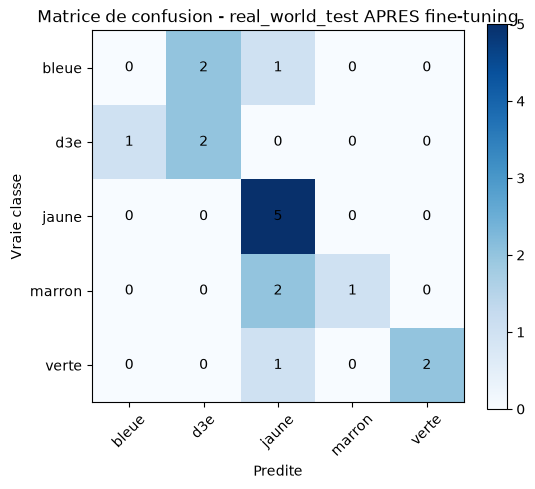

Matrice de confusion (lignes = vraie classe, colonnes = predite) :
         bleue    d3e  jaune marron  verte
 bleue       0      2      1      0      0
   d3e       1      2      0      0      0
 jaune       0      0      5      0      0
marron       0      0      2      1      0
 verte       0      0      1      0      2


In [7]:
import matplotlib.pyplot as plt

n = len(class_names)
confusion = np.zeros((n, n), dtype=int)
for t, p in zip(y_true, y_pred):
    confusion[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")
plt.xticks(range(n), class_names, rotation=45)
plt.yticks(range(n), class_names)
plt.xlabel("Predite")
plt.ylabel("Vraie classe")
for i in range(n):
    for j in range(n):
        plt.text(j, i, confusion[i, j], ha="center", va="center")
plt.title("Matrice de confusion - real_world_test APRES fine-tuning")
plt.colorbar()
plt.show()

print("Matrice de confusion (lignes = vraie classe, colonnes = predite) :")
header = "        " + " ".join(f"{c[:6]:>6s}" for c in class_names)
print(header)
for i, row in enumerate(confusion):
    print(f"{class_names[i][:6]:>6s}  " + " ".join(f"{v:6d}" for v in row))


## 6. Sauvegarde (uniquement si le resultat est meilleur)

**Ne lance cette cellule que si l'accuracy de l'etape 5 est nettement
meilleure que 47%, et que l'accuracy Kaggle (etape 4) n'a pas trop
chute.** Le modele est sauvegarde sous un nom different
(`modele_eco_sort_v2.keras`) pour pouvoir comparer avant de remplacer
l'original dans la webapp.

In [8]:
OUTPUT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model.save(OUTPUT_MODEL_PATH)
print("Modele fine-tune sauvegarde :", OUTPUT_MODEL_PATH)


Modele fine-tune sauvegarde : ..\models\modele_eco_sort_v2.keras
